# **[실습 3] KNN**

## **[실습 3-1] KNN Classifier**

### **데이터셋 설명**

400명의 인물의 나이와 연봉 정보를 토대로 특정 물품을 구매할지에 대한 결과를 가진 데이터입니다.


| 컬럼명 | 설명 |
|---|---|
| User ID| 고객 ID|
| Gender | 고객의 성별 (Male, Female) |
| Age | 고객의 나이 |
| EstimatedSalary | 고객의 추측 연봉 |
| Purchased | **[target]** 상품을 구매=1, 상품을 구매하지 않음=0|

### **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/purchased.csv

### **[1-1]. 데이터 확인하기**

#### **1. 데이터 불러오기**

**Q1. 데이터를 불러오고, 데이터의 상위 5행만 출력해보자.**

In [1]:
import pandas as  pd
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/purchased.csv")
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


#### **2. 데이터 확인하기**

**Q1. 데이터의 결측치를 확인해보자**

In [3]:
# code here
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

**Q2. 데이터의 전반적인 정보를 확인해보자**

In [4]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


**Q3. 데이터의 통계 요약을 확인해보자**

In [5]:
# code here
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


#### **3. 데이터 시각화하기**

**Q1. 남녀 성별의 비율을 파이 그래프로  그려보자.**

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

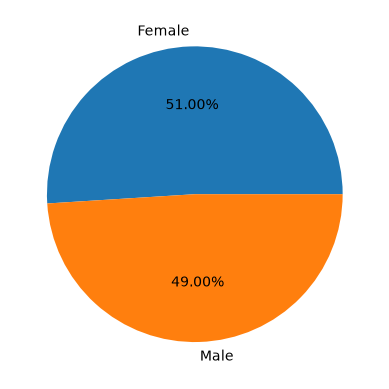

In [ ]:
# code here
import seaborn as sns
import matplotlib.pyplot as plt

df_new = df["Gender"].value_counts()
plt.pie(df_new, labels = df_new.index, autopct="%.2f%%")

**Q2. 구매를 한 사람과 구매를 하지 않은 사람들의 비율을 막대그래프로 그려보자.**

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

In [ ]:
# code here
# df.countplot(df, x = "Purchased")
df1 = pd.DataFrame((df["Purchased"].value_counts(normalize=True) * 100))
df1

,proportion
Purchased,
0,64.25
1,35.75


In [41]:
df1.index

Index([0, 1], dtype='int64', name='Purchased')

In [43]:
df1['proportion']

Purchased
0    64.25
1    35.75
Name: proportion, dtype: float64

<Axes: xlabel='Purchased'>

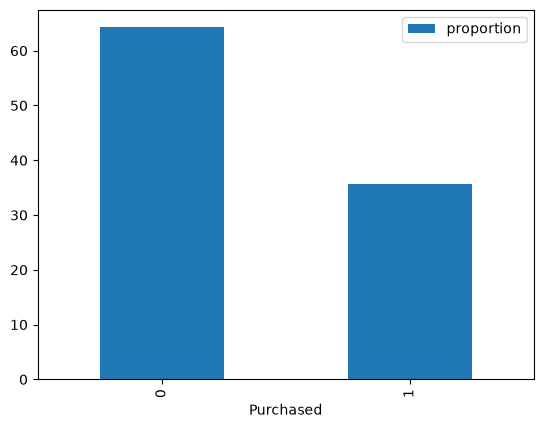

In [49]:
df1.plot(kind="bar")

**Q3. 구매를 한 사람과 구매를 하지 않은 사람들을 성별로 나눠 막대그래프로 그려보자.**

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

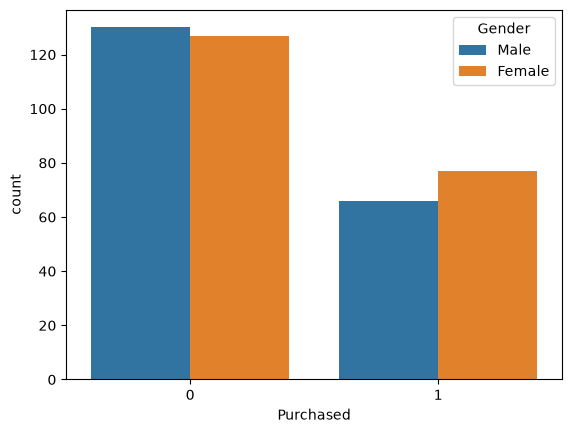

In [22]:
# code here
sns.countplot(df, x="Purchased", hue = "Gender")
plt.show()

**Q4. 사람들의 연봉 분포도를 historgram으로 그려보자.**
- kde선을 같이 그려주도록 한다.

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

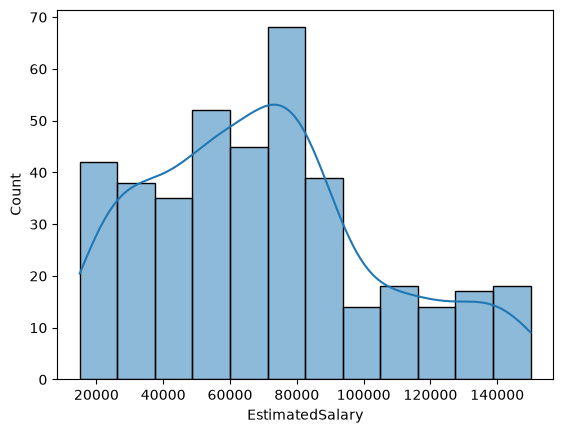

In [24]:
# code here
sns.histplot(df, x = "EstimatedSalary", kde = True)
plt.show()

**Q5. pairplot을 그려보도록 하자.**
- User ID 컬럼은 드랍시킨다.
- hue = 구매여부로 지정한다.

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

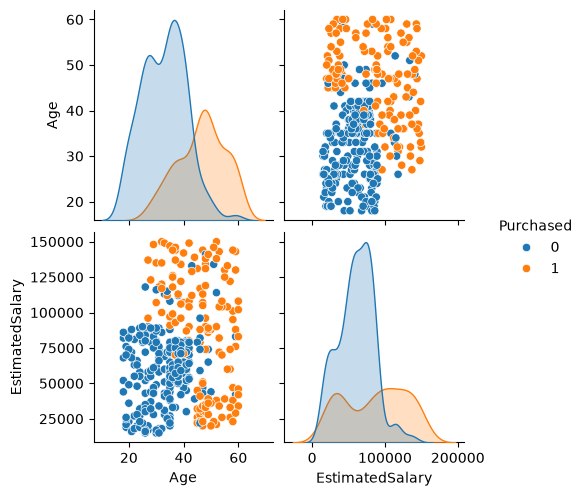

In [27]:
# code here
df2 = df.drop("User ID",axis = 1)
sns.pairplot(df2, hue="Purchased")

### **[1-2] 데이터 전처리**

In [5]:
# 전처리 과정에서 데이터가 망가지면 여기서부터 다시 실행합니다!
import pandas as  pd
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/purchased.csv")

#### **1. 데이터 삭제하기**

User ID행은 필요가 없으므로 드랍(삭제)한다.

In [6]:
#code here
df.head()
df = df.drop("User ID", axis = 1)

#### **2. 학습 데이터와 테스트 데이터로 분리하기**

- Purchased를 제외한 모든 컬럼은 X 데이터,
- Purchased 컬럼이 y로서 라벨이 된다.
- 테스트 데이터의 비중은 30%
- 재현성을 위해 random_state는 101로 설정한다.

In [7]:
# code here
X = df.drop("Purchased", axis = 1)   # Purchased 열만 드랍한 나머지 열들을 input
y = df["Purchased"]                  # 타켓 = 구매여부

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
X_train.head()

,Gender,Age,EstimatedSalary
237,Female,37,80000
268,Female,47,144000
186,Female,20,82000
106,Female,26,35000
41,Female,33,51000


#### **3. 카테고리 변수 인코딩하기**

Gender의 경우 binary (0 또는 1) 인 경우일 것이다.
- Label Encoder를 사용하거나, map()을 활용하여 데이터를 변환해보자.

In [9]:
# code here
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
X_train["Gender"] = le.fit_transform(X_train["Gender"])
X_test["Gender"] = le.transform(X_test["Gender"])


In [10]:
X_train.head()

,Gender,Age,EstimatedSalary
237,0,37,80000
268,0,47,144000
186,0,20,82000
106,0,26,35000
41,0,33,51000


### **[1-3] 모델링**

#### **1. 모델 구현하기**

**Q1. KNNClassifier class를 생성한다.**
- KNN 프로세스를 따라 K-최근접 이웃의 결과를 예측한다.

In [33]:
# code here
import numpy as np

class KNNClassifier:

    def __init__(self, k):
        self.k = k # 총 몇개의 이웃을 확인하나
        self.X = None
        self.y = None  # 이 학습 데이터와 학습라벨은 추후 새로운 정보가 들어왔을 때 -> 그냥 활용만 한다.
        self.neighbors = [] # 여기다가 k개의 최근접 이웃들의 정보를 여기 담아둠

    def fit(self, X, y):
        # lazy learning 모델로서, 실제로 학습하는건 아무것도 없음
        self.X = X
        self.y = y  # 일단 저장만 해두고, predict를 할때마다 -> 그냥 이 정보를 기반으로 예측
        # 예측 = 지금 들어온 새로운 정보를 기반으로 모든 다른 점들의 거리를 계산

    def predict(self, X):
        # X = 여러 새로운 데이터가 들어올 수 있음
        # -> 여기 새로운 데이터들을 각각 처리해서 하나의 numpy.array로 반환
        self.neighbors = []
        predictions = [] # for문을 돌며 각 i번째 데이터에 대한 분류(예측값)을 순서대로 저장해서 return 

        for x in X:
            # x에 대한 예측값을 찾기
            y_pred = self.predict_one(x) #한 정보에 대한 예측값을 정하고
            predictions.append(y_pred)
        return np.array(predictions) # numpy array로 바꿔서 return


    def get_euclidean_dist(self, a, b):
        return np.sqrt(np.sum((a - b) ** 2))



    def predict_one(self, x):
        #1. x라는 새로운 데이터로부터 다른 모든 데이터(self.x)까지의 거리를 모두 구한다
        dists = [self.get_euclidean_dist(x, data) for data in self.X]
        
        #2. 정렬 -> 거리 기반으로 정렬 하지만 나중에 쓸 것은 거리는 아님
        indexes = np.argsort(dists)[:self.k]
    
        #3. 거기서 맨 앞의 self.k만큼만 잘라서 -> 이 정보들을 self.neighbors에 저장
        self.neighbors.append(indexes)

        #4. 이 맨 앞의 self.k만큼만 잘라서 -> 이 정보들을 self.neighbors에 저장
        labels = [self.y.iloc[i] for i in indexes]
         
        y_pred = np.argmax(np.bincount(labels))
        return y_pred


#### **2. 모델 생성, 학습하기**

**Q1. KNN 모델을 생성한다.**
- 확인할 K-최근접 이웃의 개수 (K value)는 5로 설정한다.

In [34]:
# code here
model = KNNClassifier(5)
model.fit(X_train.values, y_train)

**Q2. 모델을 학습 데이터로 학습시킨다.**

In [35]:
# code here
model.fit(X_train.values, y_train)

#### **3. 모델 예측하기**

**Q1. 테스트 데이터(X_test)의 예측 결과를 y_pred에 저장한다.**

In [36]:
# code here
y_pred = model.predict(X_test.values)

#### **4. 모델 평가하기**

**Q1. 혼동 행렬을 그려 모델을 평가한다.**

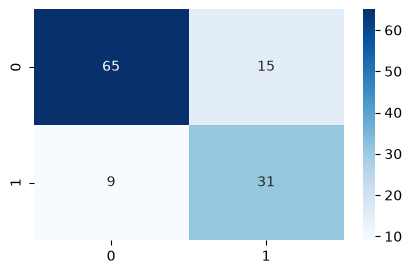

In [40]:
# code here
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(5,3))
sns.heatmap(confusion_matrix(y_test, y_pred),  cmap = 'Blues', annot=True)
plt.show()


**Q2. 정확도를 출력하여 모델을 평가한다.**

In [44]:
# code here
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

print(f"report: {classification_report(y_test, y_pred)}")
print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100}%")

report:               precision    recall  f1-score   support

           0       0.88      0.81      0.84        80
           1       0.67      0.78      0.72        40

    accuracy                           0.80       120
   macro avg       0.78      0.79      0.78       120
weighted avg       0.81      0.80      0.80       120

Accuracy: 80.0%


### **[1-4] 결과 이해하기**

**Q1. 새로운 데이터의 예측 결과를 내보자.**

약 45살에 30000달러정도의 연봉이면, 구매를 했다 (Purchased=1) 이라는 결과가 나올것으로 예상할 수 있다.

In [45]:
# code here
new_data = np.array([[1, 45, 30000]])
pred = model.predict(new_data)
print(pred)

[1]


**Q2. 가까운 이웃 출력하기**
- knn.neighbors에는 참고한 k=5개의 이웃의 index가 기록되어있다.

In [ ]:
# code here 
model.neighbors  #iloc index

[array([176,  64,  28, 187, 207])]

**Q3. 가까운 이웃 를 하나씩 확인해보자.**

In [ ]:
# code here
X_train.iloc[model.neighbors[0]]

# code here
y_train.iloc[model.neighbors[0]]

,Gender,Age,EstimatedSalary
27,0,47,30000
323,0,48,30000
158,1,26,30000
131,1,33,31000
365,0,59,29000


**Q4. 가까운 이웃들을 산점도 그래프에 어딨는지 표기해보자.**

그리고 이상한 점을 확인해보자.

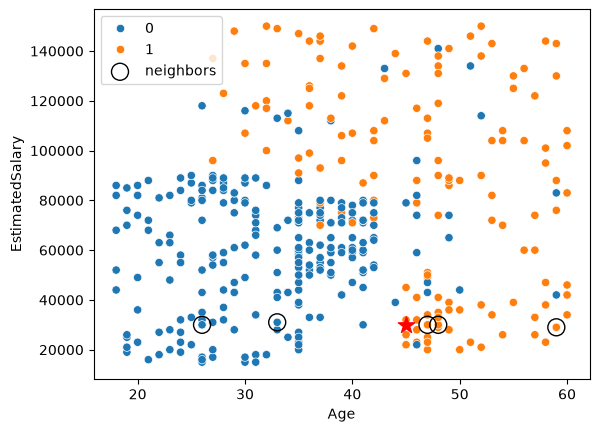

In [ ]:
#code here
sns.scatterplot(df, x = "Age", y = "EstimatedSalary", hue = "Purchased")
# 새로운 데이터가 어디에 있는지 
plt.scatter( 45, 30000, marker="*", color = "red", s = 150)
# neighbor들에 대해서 어딨는 애들인지 표기
plt.scatter(
    x = X_train.iloc[model.neighbors[0]]["Age"],
    y = X_train.iloc[model.neighbors[0]]["EstimatedSalary"],
    label ="neighbors",
    edgecolors="black",
    facecolor = 'none',
    s = 150
)
plt.legend()
plt.show()
# 왜 가장 가까운 5개를 취해야 하는데 이상한 애들이 잡혀오나

## **[실습 3-2] Feature Scaling**

### **[2-1] Feature Scaling 해보기**

#### **1. Normalization**

**Q1 정규화를 해보자.**
- 학습 데이터를 X_train_copy에 복사해둔다.
- 테스트 데이터를 X_test_copy에 복사해둔다.
- 그리고 sklearn의 MinMaxScaler를 활용하여 정규화를 해보자.

```
from sklearn.preprocesing import MinMaxScaler
scaler = MinMaxScaler()
```

테스트 데이터는 반드시 학습 데이터를 학습시킨 Scaler를 활용하여 data leakage를 방지한다.

In [58]:
X_train_copy = X_train.copy()

In [59]:
# code here
# 정규화 (normalization)
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_copy = scaler.fit_transform(X_train_copy)
X_train_copy

array([[0.        , 0.45238095, 0.48148148],
       [0.        , 0.69047619, 0.95555556],
       [0.        , 0.04761905, 0.4962963 ],
       [0.        , 0.19047619, 0.14814815],
       [0.        , 0.35714286, 0.26666667],
       [0.        , 0.21428571, 0.9037037 ],
       [1.        , 0.64285714, 0.47407407],
       [0.        , 0.07142857, 0.00740741],
       [1.        , 0.42857143, 0.95555556],
       [0.        , 0.66666667, 0.6       ],
       [1.        , 0.16666667, 0.48148148],
       [1.        , 0.19047619, 0.48148148],
       [0.        , 0.64285714, 0.85925926],
       [1.        , 0.0952381 , 0.48888889],
       [1.        , 0.54761905, 0.27407407],
       [0.        , 0.57142857, 0.28148148],
       [0.        , 0.23809524, 0.53333333],
       [0.        , 0.54761905, 0.26666667],
       [1.        , 0.5       , 0.2       ],
       [0.        , 0.57142857, 0.68888889],
       [1.        , 0.21428571, 0.03703704],
       [1.        , 0.54761905, 0.47407407],
       [0.

#### **2. Standardization**

**Q1 표준화를 해보자.**
- 학습 데이터를 X_train_copy에 복사해둔다.
- 테스트 데이터를 X_test_copy에 복사해둔다.
- 그리고 sklearn의 MinMaxScaler를 활용하여 정규화를 해보자.

```
from sklearn.preprocesing import StandardScaler
scaler = StandardScaler()
```

테스트 데이터는 반드시 학습 데이터를 학습시킨 Scaler를 활용하여 data leakage를 방지한다.

In [ ]:
#code here
X_train_copy = X_train.copy()

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_copy = scaler.fit_transform(X_train_copy)
X_train_copy

array([[-0.96490128, -0.07024299,  0.30553739],
       [-0.96490128,  0.88917351,  2.20864132],
       [-0.96490128, -1.70125106,  0.36500939],
       [-0.96490128, -1.12560115, -1.03258256],
       [-0.96490128, -0.4540096 , -0.55680658],
       [-0.96490128, -1.0296595 ,  2.00048933],
       [ 1.03637545,  0.69729021,  0.27580139],
       [-0.96490128, -1.60530941, -1.59756654],
       [ 1.03637545, -0.16618465,  2.20864132],
       [-0.96490128,  0.79323186,  0.78131337],
       [ 1.03637545, -1.2215428 ,  0.30553739],
       [ 1.03637545, -1.12560115,  0.30553739],
       [-0.96490128,  0.69729021,  1.82207333],
       [ 1.03637545, -1.50936776,  0.33527339],
       [ 1.03637545,  0.31352361, -0.52707058],
       [-0.96490128,  0.40946526, -0.49733458],
       [-0.96490128, -0.93371785,  0.51368938],
       [-0.96490128,  0.31352361, -0.55680658],
       [ 1.03637545,  0.12164031, -0.82443057],
       [-0.96490128,  0.40946526,  1.13814536],
       [ 1.03637545, -1.0296595 , -1.478

### **[2-2] 데이터 스케일링**

**Q1. 학습 데이터를 기반으로 표준화를 진행한다.**
- 그리고 같은 scaler를 가지고 테스트 데이터를 표준화한다.
- X_train은 X_train_scaled에, X_test는 X_test_scaled에 저장한다
- 원본 데이터 (X_train, y_train)는 최종적으로 시각화를 할때 사용할 것이므로, 손상되게 해서는 안된다.

In [ ]:
# code here
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

array([[-0.96490128, -0.07024299,  0.30553739],
       [-0.96490128,  0.88917351,  2.20864132],
       [-0.96490128, -1.70125106,  0.36500939],
       [-0.96490128, -1.12560115, -1.03258256],
       [-0.96490128, -0.4540096 , -0.55680658],
       [-0.96490128, -1.0296595 ,  2.00048933],
       [ 1.03637545,  0.69729021,  0.27580139],
       [-0.96490128, -1.60530941, -1.59756654],
       [ 1.03637545, -0.16618465,  2.20864132],
       [-0.96490128,  0.79323186,  0.78131337],
       [ 1.03637545, -1.2215428 ,  0.30553739],
       [ 1.03637545, -1.12560115,  0.30553739],
       [-0.96490128,  0.69729021,  1.82207333],
       [ 1.03637545, -1.50936776,  0.33527339],
       [ 1.03637545,  0.31352361, -0.52707058],
       [-0.96490128,  0.40946526, -0.49733458],
       [-0.96490128, -0.93371785,  0.51368938],
       [-0.96490128,  0.31352361, -0.55680658],
       [ 1.03637545,  0.12164031, -0.82443057],
       [-0.96490128,  0.40946526,  1.13814536],
       [ 1.03637545, -1.0296595 , -1.478

### **[2-3]. 모델링**

**Q1. KNN 분류기를 생성하고, scaling된 데이터를 기반으로 학습하도록 한다.**

In [64]:
# code here
model.fit(X_train, y_train)

### **[2-4]. 모델 예측, 평가하기**

**Q1. 테스트 데이터로 나온 예측 결과를 y_pred로 저장한다.**

In [65]:
# code here
y_pred = model.predict(X_test)

**Q2. 혼동 행렬과 정확도, 그리고 분류 리포트를 확인한다.**

0.9416666666666667


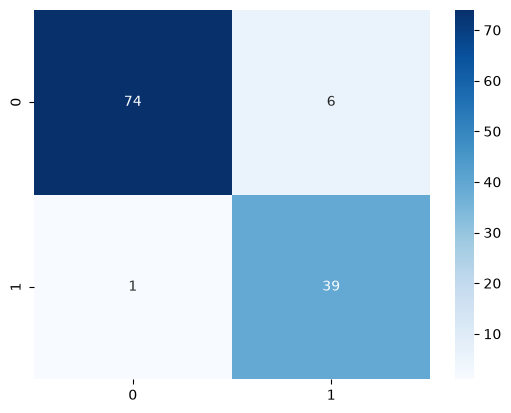

In [ ]:
# code here
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, cmap='Blues')
print(accuracy_score(y_test, y_pred))

### **[2-5]. 결과 이해하기**

**Q1. 새로운 데이터의 예측 결과를 내보자.**

다시 45살에 30000달러정도의 연봉인 사람의 결과를 예측해보자.

그리고 이번에도 나온 이웃들을 산점도 그래프에 표시해보자.

In [68]:
# code here
new_data = np.array([[1, 45, 30000]])
new_data_scaled = scaler.transform(new_data)
print(new_data_scaled)

[[ 1.03637545  0.69729021 -1.18126256]]


c:\Users\user\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [70]:
y_pred = model.predict(new_data_scaled)
print(y_pred)

[1]


In [76]:
model.neighbors

[array([ 41,  44, 143, 102,  93])]

## **[실습 3-3] 최적의 K값 찾기**

### **[3-1]. Elbow Method**

**Q1. Elbow Method를 활용해서 최적의 K값 (Optimal K-value)를 찾아보자.**

In [77]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

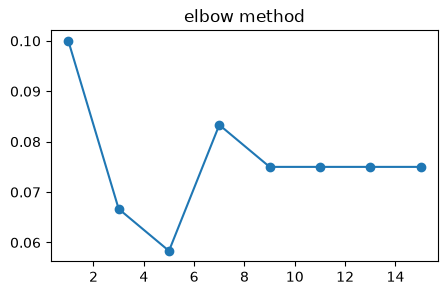

In [ ]:
# code here
# 1 ~ n까지 홀수들만 시도
def elbow_method(n):
    errors = []
    for k in range(1, n+1, 2):
        knn_model = KNNClassifier(k)
        knn_model.fit(X_train_scaled, y_train)
        # 예측
        y_pred = knn_model.predict(X_test_scaled)
        errors.append((y_pred != y_test).mean())


    # 테스트 다 끝난다음, 시각화
    plt.figure(figsize=(5,3))
    plt.title("elbow method")
    plt.plot(range(1, n+1, 2), errors, marker='o')
    plt.show()

elbow_method(15)

### **[3-2]. 모델링**

**Q1. 새로 찾은 최적의 K값으로 변경해서 학습시켜보자.**

- 다른 값으로 바꿔서 성능이 어떻게 바뀌는지 확인해보자.

In [ ]:
# code here
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(5)  # n_neighbors = n, metrics = eculidian, manhatton.. 
model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
# 각 데이터별로 n_neighbors 개수만큼 거리와 index를 알아올 수 있다.
model.kneighbors()

(array([[0.059472  , 0.17694785, 0.19417371, 0.2116064 , 0.2427446 ],
        [0.2116064 , 0.31245442, 0.32395824, 0.38834743, 0.43157156],
        [0.        , 0.28782495, 0.43658225, 0.55606294, 0.57871386],
        ...,
        [0.118944  , 0.118944  , 0.1918833 , 0.20815199, 0.22575844],
        [0.11287922, 0.17694785, 0.20257608, 0.2116064 , 0.2116064 ],
        [0.089208  , 0.118944  , 0.14867999, 0.15281516, 0.1918833 ]],
       shape=(280, 5)),
 array([[ 32, 197,  43,  79, 101],
        [108,  23, 167, 269,  12],
        [259, 155, 131, 243, 219],
        ...,
        [ 50, 229, 202,  55, 279],
        [213, 203, 132,  24,  63],
        [116, 202, 215, 217,  50]], shape=(280, 5)))

### **[3-3] 모델 평가**

**Q1. 정확도, 혼동행렬, 분류 리포트등을 통해 위에서 정한 K-최근접 이웃의 성능을 확인하자.**

<Axes: >

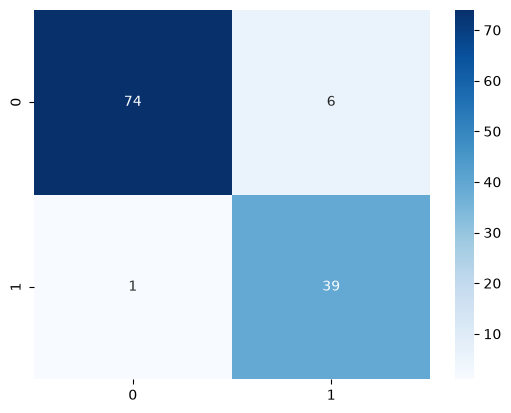

In [91]:
# code here
y_pred = model.predict(X_test_scaled)

sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, cmap = "Blues")

In [92]:
print(accuracy_score(y_pred, y_test))

0.9416666666666667
